In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

Text(0, 0.5, 'Y dataset')

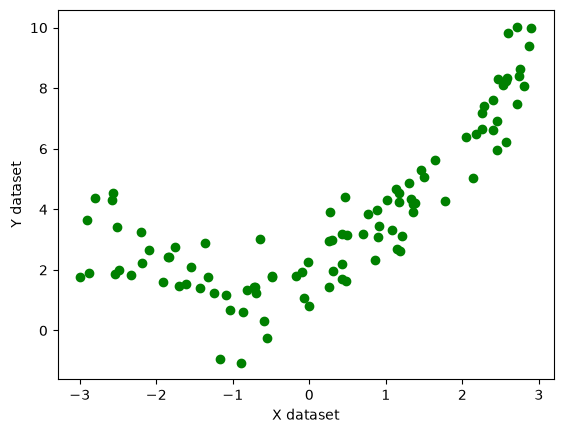

In [3]:
# create a dataset
X = 6 * np.random.rand(100, 1) - 3 # random to get some outliers
Y = 0.5 * X**2 + X + 2 + np.random.randn(100, 1)
plt.scatter(X,Y,color='g')
plt.xlabel('X dataset')
plt.ylabel('Y dataset')

In [4]:
# check what is the error in linear dataset.
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [7]:
# lets implement a simple linear regression
from sklearn.linear_model import LinearRegression
regession1 = LinearRegression()

In [8]:
# we don't neet to scale the values because it's already small enough to use.
regession1.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[1.2]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3.46]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[15.06]


In [ ]:
from sklearn.metrics import r2_score
score = r2_score(Y_test,regession1.predict(X_test))
print(score)
# very very low accuracy.

0.261339373036944


Text(0, 0.5, 'Y dataset')

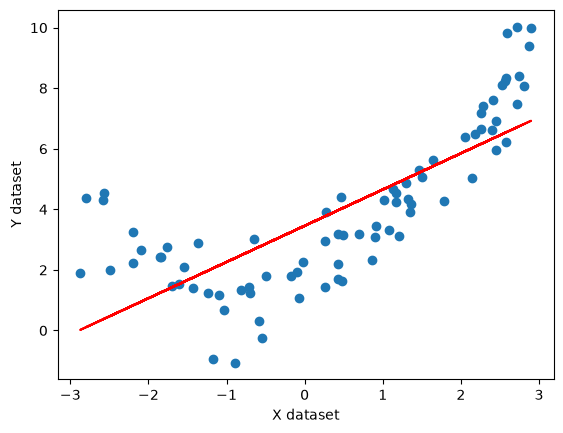

In [12]:
## visualization 
plt.plot(X_train,regession1.predict(X_train),color='r')
plt.scatter(X_train,Y_train)
plt.xlabel('X dataset')
plt.ylabel('Y dataset')

In [14]:
# solve this issue using polynomial regression.
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2,include_bias=True)
#include bais includes the beta not also with x to the power 1.

In [15]:
X_train_poly = poly.fit_transform(X_train) # main data of transform is training data not test
X_test_poly = poly.transform(X_test)

In [ ]:
X_train_poly
#(bais, x1 feature, x2 feature)
# now we have 3 feature before we only have one.

array([[ 1.00000000e+00,  2.25334182e+00,  5.07754935e+00],
       [ 1.00000000e+00,  1.16896447e+00,  1.36647792e+00],
       [ 1.00000000e+00, -2.87359470e+00,  8.25754649e+00],
       [ 1.00000000e+00,  2.39552712e+00,  5.73855019e+00],
       [ 1.00000000e+00, -2.56845412e+00,  6.59695655e+00],
       [ 1.00000000e+00,  4.26677946e-01,  1.82054070e-01],
       [ 1.00000000e+00,  1.77892682e+00,  3.16458063e+00],
       [ 1.00000000e+00,  1.64586055e+00,  2.70885695e+00],
       [ 1.00000000e+00,  4.30883651e-01,  1.85660721e-01],
       [ 1.00000000e+00, -1.84543931e+00,  3.40564626e+00],
       [ 1.00000000e+00,  1.30354081e+00,  1.69921865e+00],
       [ 1.00000000e+00,  1.08574943e+00,  1.17885183e+00],
       [ 1.00000000e+00,  1.16874135e+00,  1.36595634e+00],
       [ 1.00000000e+00,  2.25307216e+00,  5.07633416e+00],
       [ 1.00000000e+00,  9.08298459e-01,  8.25006090e-01],
       [ 1.00000000e+00,  1.13544534e+00,  1.28923612e+00],
       [ 1.00000000e+00,  2.13885371e+00

In [17]:
regression2 = LinearRegression()
regression2.fit(X_train_poly,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[0. ,0.96,0.55]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1.9]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[24.52,14.16, 0. ]"


In [18]:
Y_pred = regression2.predict(X_test_poly)
score = r2_score(Y_test, Y_pred)
print(score)

0.8359218023554755


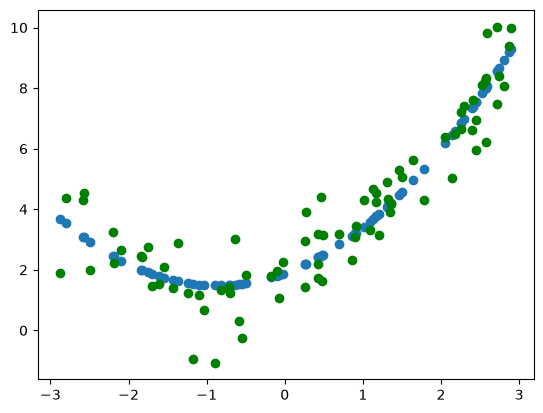

In [20]:
plt.scatter(X_train,regression2.predict(X_train_poly))
plt.scatter(X_train,Y_train, color = 'g')

In [21]:
# now if we do the degree = 3 then we get the four features after poly transform, and then when we test the r2 score it will (sometimes it descrease sometimes it increse or sometimes it stays closer) that's why chossing correct degree is imp

# predict for a new dataset
X_new = np.linspace(-3,3,200).reshape(200,1)
X_new_poly = poly.transform(X_new)

In [32]:
X_new_poly


array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00],
       [ 1.00000000e+00, -2.96984925e+00,  8.82000455e+00],
       [ 1.00000000e+00, -2.93969849e+00,  8.64182723e+00],
       [ 1.00000000e+00, -2.90954774e+00,  8.46546804e+00],
       [ 1.00000000e+00, -2.87939698e+00,  8.29092700e+00],
       [ 1.00000000e+00, -2.84924623e+00,  8.11820409e+00],
       [ 1.00000000e+00, -2.81909548e+00,  7.94729931e+00],
       [ 1.00000000e+00, -2.78894472e+00,  7.77821267e+00],
       [ 1.00000000e+00, -2.75879397e+00,  7.61094417e+00],
       [ 1.00000000e+00, -2.72864322e+00,  7.44549380e+00],
       [ 1.00000000e+00, -2.69849246e+00,  7.28186157e+00],
       [ 1.00000000e+00, -2.66834171e+00,  7.12004747e+00],
       [ 1.00000000e+00, -2.63819095e+00,  6.96005151e+00],
       [ 1.00000000e+00, -2.60804020e+00,  6.80187369e+00],
       [ 1.00000000e+00, -2.57788945e+00,  6.64551400e+00],
       [ 1.00000000e+00, -2.54773869e+00,  6.49097245e+00],
       [ 1.00000000e+00, -2.51758794e+00

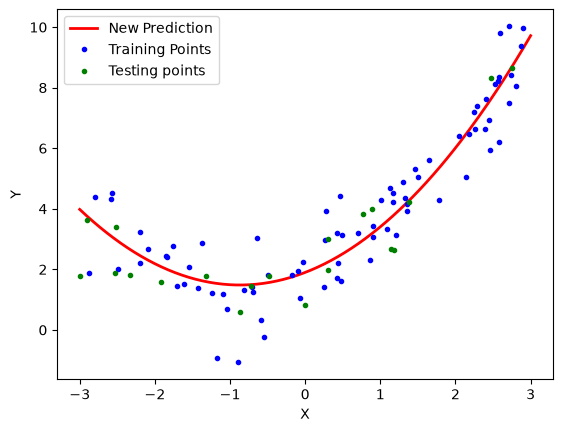

In [31]:
Y_new = regression2.predict(X_new_poly)
plt.plot(X_new,Y_new,"r-",linewidth=2,label='New Prediction')
plt.plot(X_train,Y_train,'b.', label ="Training Points")
plt.plot(X_test,Y_test,'g.',label='Testing points')
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

### Pipelining concept

In [33]:
from sklearn.pipeline import Pipeline

In [ ]:
def poly_regression(degree):
    X_new = np.linspace(-3,3,200).reshape(200,1)
    poly_features = PolynomialFeatures(degree=degree,include_bias=True)
    lin_reg = LinearRegression()
    poly_regression = Pipeline([
        ("poly_features",poly_features),
        ("lin_reg",lin_reg)
    ])
    poly_regression.fit(X_train,Y_train)
    Y_pred_new = poly_regression.predict(X_new)
    # plotting prediction line.
    plt.plot(X_new,Y_pred_new,'r', label ="Degree "+str(degree), linewidth=2)
    plt.plot(X_train,Y_train,"b.",linewidth=3)
    plt.plot(X_test,Y_test,"g.",linewidth=3)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis([-4,4,0,10])
    plt.show

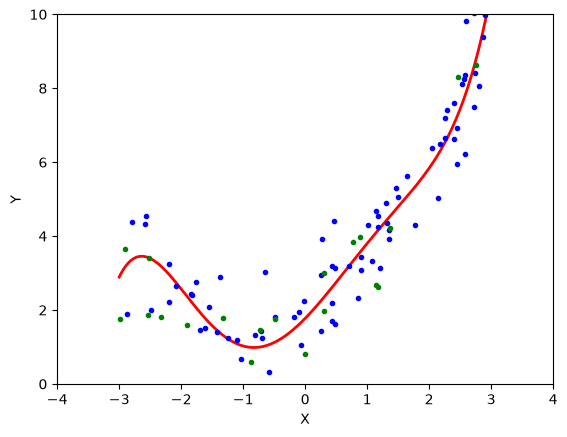

In [42]:
poly_regression(5)
# as we increase the degree higher it starts overfitting the data